# NYC Yellow Taxi Trips: My Analysis of Ride Duration
**CS672 — Fall 2026 | Project 1 | Due October 16, 2026**

**Negar Kamvij**

## My research question
Which features are related to how long a taxi ride takes?

In this project, I examine NYC Yellow Taxi records, investigate data quality, analyze relationships with trip duration, and compare March with May 2020. My notebook brings together my code, results, visualizations, and conclusions.

- **March 2020:** my training dataset.
- **May 2020:** my evaluation dataset.
- **January 2020:** my baseline dataset for the completed extra-credit comparison with March.

## 1. My analysis tools
My analysis uses pandas, NumPy, Matplotlib, seaborn, and TensorFlow Data Validation (TFDV). The assignment also specifies Apache Beam and GraphViz. GraphViz requires a system application in addition to its Python wrapper.

For reproducibility, TFDV installation and Python compatibility guidance are available in the [official installation guide](https://www.tensorflow.org/tfx/data_validation/install).

In [ ]:
# Optional environment setup. Installed versions are recorded below.
%pip install pandas numpy matplotlib seaborn pyarrow tensorflow-data-validation "apache-beam[interactive]" graphviz

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = Path("data")
DATA_DIR.mkdir(parents=True, exist_ok=True)


In [2]:
import sys, shutil, subprocess
from importlib.metadata import version
for package in ["pandas", "numpy", "pyarrow", "tensorflow-data-validation", "apache-beam", "graphviz"]:
    print(package, version(package))
print("Python:", sys.version.split()[0])
assert shutil.which("dot"), "Install the GraphViz system application (dot) before running."
print(subprocess.check_output(["dot", "-V"], stderr=subprocess.STDOUT, text=True).strip())


pandas 2.3.3
numpy 2.4.6
pyarrow 25.0.1
tensorflow-data-validation 1.21.0
apache-beam 2.77.0
graphviz 0.21
Python: 3.13.3
dot - graphviz version 16.1.0 (20260904.0139)


## 2. My data sources
I use March and May 2020 **Yellow Taxi** trip records from the [NYC Taxi & Limousine Commission](https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page).

The input files are `yellow_tripdata_2020-03.parquet` and `yellow_tripdata_2020-05.parquet`. Their location is controlled by `DATA_DIR` in the setup cell. I read the Parquet files directly with pandas.

My summary statistics use the full datasets at the relevant cleaning stage. My scatterplots use a reproducible sample of up to 5,000 retained trips per month for readability.

In [3]:
paths = {"March": DATA_DIR / "yellow_tripdata_2020-03.parquet",
         "May": DATA_DIR / "yellow_tripdata_2020-05.parquet"}
missing = [str(path) for path in paths.values() if not path.exists()]
if missing:
    raise FileNotFoundError("Download these files first: " + ", ".join(missing))
raw = {month: pd.read_parquet(path) for month, path in paths.items()}
display(raw["March"].head())


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee
0,1,2020-03-01 00:31:13,2020-03-01 01:01:42,1.0,4.70,1.0,N,88,255,1,22.0,3.0,0.5,2.00,0.0,0.3,27.80,2.5,None
1,2,2020-03-01 00:08:22,2020-03-01 00:08:49,1.0,0.00,1.0,N,193,193,2,2.5,0.5,0.5,0.00,0.0,0.3,3.80,0.0,None
2,1,2020-03-01 00:52:18,2020-03-01 00:59:16,1.0,1.10,1.0,N,246,90,1,6.0,3.0,0.5,1.95,0.0,0.3,11.75,2.5,None
3,2,2020-03-01 00:47:53,2020-03-01 00:50:57,2.0,0.87,1.0,N,151,238,1,5.0,0.5,0.5,1.76,0.0,0.3,10.56,2.5,None
4,1,2020-03-01 00:43:19,2020-03-01 00:58:27,0.0,4.40,1.0,N,79,261,1,16.5,3.0,0.5,4.05,0.0,0.3,24.35,2.5,None


## 3. My initial data inspection
I count the records, inspect storage types, summarize missing values, and check for exact duplicates before cleaning. I distinguish how a column is stored from what it represents: a numeric code can be a category rather than a continuous measurement.

In [4]:
for month, frame in raw.items():
    print(month, "rows:", len(frame), "columns:", len(frame.columns))
    display(pd.DataFrame({"stored_type": frame.dtypes.astype(str),
                          "missing_count": frame.isna().sum(),
                          "missing_percent": frame.isna().mean() * 100}))
    display(frame.describe(include="all").T)
    print("Exact duplicate rows:", frame.duplicated().sum())


March rows: 3007687 columns: 19
Exact duplicate rows: 0
May rows: 348415 columns: 19
Exact duplicate rows: 0


,stored_type,missing_count,missing_percent
VendorID,int64,0,0.000000
tpep_pickup_datetime,datetime64[us],0,0.000000
tpep_dropoff_datetime,datetime64[us],0,0.000000
passenger_count,float64,37808,1.257046
trip_distance,float64,0,0.000000
RatecodeID,float64,37808,1.257046
store_and_fwd_flag,object,37808,1.257046
PULocationID,int64,0,0.000000
DOLocationID,int64,0,0.000000
payment_type,int64,0,0.000000


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
VendorID,3007687.0,NaN,NaN,NaN,1.671989,1.0,1.0,2.0,2.0,6.0,0.472886
tpep_pickup_datetime,3007687,NaN,NaN,NaN,2020-03-09 01:48:50.541679,2008-12-31 23:02:19,2020-03-04 18:26:35,2020-03-07 22:31:41,2020-03-12 08:23:20,2020-08-27 15:16:15,NaN
tpep_dropoff_datetime,3007687,NaN,NaN,NaN,2020-03-09 02:04:25.845666,2008-12-31 23:35:21,2020-03-04 18:43:22,2020-03-07 22:46:40,2020-03-12 08:39:24,2020-08-27 15:21:14,NaN
passenger_count,2969879.0,NaN,NaN,NaN,1.467477,0.0,1.0,1.0,1.0,9.0,1.120087
trip_distance,3007687.0,NaN,NaN,NaN,3.117041,0.0,1.0,1.67,3.02,269803.73,206.920728
RatecodeID,2969879.0,NaN,NaN,NaN,1.051377,1.0,1.0,1.0,1.0,99.0,0.710921
store_and_fwd_flag,2969879,2,N,2941898,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PULocationID,3007687.0,NaN,NaN,NaN,163.429781,1.0,114.0,162.0,234.0,265.0,66.586537
DOLocationID,3007687.0,NaN,NaN,NaN,160.933627,1.0,107.0,162.0,234.0,265.0,70.741316
payment_type,3007687.0,NaN,NaN,NaN,1.251811,0.0,1.0,1.0,2.0,4.0,0.49412


,stored_type,missing_count,missing_percent
VendorID,int64,0,0.000000
tpep_pickup_datetime,datetime64[us],0,0.000000
tpep_dropoff_datetime,datetime64[us],0,0.000000
passenger_count,float64,58901,16.905415
trip_distance,float64,0,0.000000
RatecodeID,float64,58901,16.905415
store_and_fwd_flag,object,58901,16.905415
PULocationID,int64,0,0.000000
DOLocationID,int64,0,0.000000
payment_type,int64,0,0.000000


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
VendorID,348415.0,NaN,NaN,NaN,1.630091,1.0,1.0,2.0,2.0,6.0,0.484691
tpep_pickup_datetime,348415,NaN,NaN,NaN,2020-05-16 21:47:01.946934,2008-12-31 23:05:47,2020-05-09 07:18:24,2020-05-16 17:19:02,2020-05-24 16:28:31,2020-11-01 15:41:04,NaN
tpep_dropoff_datetime,348415,NaN,NaN,NaN,2020-05-16 22:00:32.603673,2008-12-31 23:33:33,2020-05-09 07:34:38.500000,2020-05-16 17:31:49,2020-05-24 16:42:16.500000,2020-11-01 15:57:02,NaN
passenger_count,289514.0,NaN,NaN,NaN,1.314171,0.0,1.0,1.0,1.0,9.0,0.983983
trip_distance,348415.0,NaN,NaN,NaN,8.333053,0.0,1.05,1.99,4.25,297004.51,774.817906
RatecodeID,289514.0,NaN,NaN,NaN,1.043062,1.0,1.0,1.0,1.0,99.0,0.96945
store_and_fwd_flag,289514,2,N,286687,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PULocationID,348415.0,NaN,NaN,NaN,152.597822,1.0,90.0,143.0,231.0,265.0,70.864142
DOLocationID,348415.0,NaN,NaN,NaN,148.483274,1.0,75.0,143.0,230.0,265.0,74.815894
payment_type,348415.0,NaN,NaN,NaN,1.182598,0.0,1.0,1.0,2.0,4.0,0.734705


In [5]:
for month, frame in raw.items():
    print("\n==========", month.upper(), "==========")
    print("Number of rides:", len(frame))
    print("Number of columns:", len(frame.columns))

    print("\nMissing values:")
    missing_summary = frame.isna().sum()
    print(missing_summary[missing_summary > 0].sort_values(ascending=False))

    print("\nPickup date range:")
    print("Earliest:", frame["tpep_pickup_datetime"].min())
    print("Latest:  ", frame["tpep_pickup_datetime"].max())

    print("\nTrip distance:")
    print(frame["trip_distance"].describe())

    print("\nPassenger count:")
    print(frame["passenger_count"].describe())

    print("\nExact duplicates:", frame.duplicated().sum())


========== MARCH ==========
Number of rides: 3007687
Number of columns: 19

Missing values:
airport_fee             3007687
passenger_count           37808
RatecodeID                37808
store_and_fwd_flag        37808
congestion_surcharge      37808
dtype: int64

Pickup date range:
Earliest: 2008-12-31 23:02:19
Latest:   2020-08-27 15:16:15

Trip distance:
count    3.007687e+06
mean     3.117041e+00
std      2.069207e+02
min      0.000000e+00
25%      1.000000e+00
50%      1.670000e+00
75%      3.020000e+00
max      2.698037e+05
Name: trip_distance, dtype: float64

Passenger count:
count    2.969879e+06
mean     1.467477e+00
std      1.120087e+00
min      0.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      9.000000e+00
Name: passenger_count, dtype: float64

Exact duplicates: 0

========== MAY ==========
Number of rides: 348415
Number of columns: 19

Missing values:
airport_fee             348415
passenger_count          58901
RatecodeID           

### My observations about data types and missing values

| Type of information | Columns | My interpretation |
| --- | --- | --- |
| Datetime | `tpep_pickup_datetime`, `tpep_dropoff_datetime` | I use these to calculate duration and derive pickup-time features. |
| Numeric count and distance | `passenger_count`, `trip_distance` | I inspect missing values, zero values, and extreme observations. |
| Numeric monetary amounts | `fare_amount`, `extra`, `mta_tax`, `tip_amount`, `tolls_amount`, `improvement_surcharge`, `total_amount`, `congestion_surcharge`, `airport_fee` | These describe charges; I exclude them from my final selected prediction inputs. |
| Categorical codes | `VendorID`, `RatecodeID`, `PULocationID`, `DOLocationID`, `payment_type` | Their numeric storage does not imply a meaningful numeric order. |
| Categorical text | `store_and_fwd_flag` | This is a category, not a numeric measurement. |

I found no exact duplicate rows in either original dataset. Passenger count and several other fields contain missing values. `airport_fee` is completely missing in both months, so I exclude it from my selected inputs rather than inventing values.

## 4. My duration calculation and outlier investigation
I calculate ride duration as drop-off time minus pickup time, in minutes. I inspect extreme records and distribution summaries before choosing filters. I exclude nonpositive durations from this positive-duration study; unusually long trips need further investigation rather than automatic assumptions about their cause.

In [6]:
def add_duration(frame):
    result = frame.copy()
    for col in ["tpep_pickup_datetime", "tpep_dropoff_datetime"]:
        result[col] = pd.to_datetime(result[col], errors="coerce")
    result["trip_duration_minutes"] = (
        result["tpep_dropoff_datetime"] - result["tpep_pickup_datetime"]
    ).dt.total_seconds() / 60
    return result

prepared = {month: add_duration(frame) for month, frame in raw.items()}
for month, frame in prepared.items():
    print(month)
    display(frame[["trip_duration_minutes", "trip_distance"]].describe(
        percentiles=[.01, .5, .95, .99]))
    display(frame.nlargest(5, "trip_duration_minutes"))


March
May


,trip_duration_minutes,trip_distance
count,3.007687e+06,3.007687e+06
mean,1.558840e+01,3.117041e+00
std,6.558050e+01,2.069207e+02
min,-4.746262e+04,0.000000e+00
1%,9.000000e-01,0.000000e+00
50%,1.040000e+01,1.670000e+00
95%,3.276667e+01,1.023000e+01
99%,5.436667e+01,1.888000e+01
max,1.814817e+03,2.698037e+05


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,trip_duration_minutes
903843,2,2020-03-05 12:46:56,2020-03-06 19:01:45,3.0,0.64,1.0,N,238,263,2,5.0,1.0,0.5,0.00,0.0,0.3,9.30,2.5,None,1814.816667
904339,2,2020-03-05 12:46:56,2020-03-06 18:57:23,1.0,2.90,1.0,N,238,142,2,45.0,0.0,0.5,0.00,0.0,0.3,48.30,2.5,None,1810.450000
2634594,2,2020-03-15 15:06:30,2020-03-16 15:06:29,1.0,0.00,1.0,N,152,166,2,2.5,0.0,0.5,0.00,0.0,0.3,5.80,0.0,None,1439.983333
1234714,2,2020-03-06 18:49:43,2020-03-07 18:49:39,2.0,0.86,1.0,N,161,186,1,8.0,1.0,0.5,1.23,0.0,0.3,13.53,2.5,None,1439.933333
666728,2,2020-03-04 12:06:54,2020-03-05 12:06:40,1.0,3.08,1.0,N,48,43,2,13.5,0.0,0.5,0.00,0.0,0.3,16.80,2.5,None,1439.766667


,trip_duration_minutes,trip_distance
count,348415.000000,348415.000000
mean,13.510946,8.333053
std,47.169801,774.817906
min,-0.333333,0.000000
1%,0.366667,0.000000
50%,8.950000,1.990000
95%,32.000000,13.500000
99%,47.000000,21.110000
max,1438.866667,297004.510000


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,trip_duration_minutes
14176,2,2020-05-02 15:48:31,2020-05-03 15:47:23,1.0,5.02,1.0,N,68,41,2,18.5,0.0,0.5,0.0,0.0,0.3,21.8,2.5,None,1438.866667
196701,2,2020-05-22 16:49:41,2020-05-23 16:48:11,1.0,1.48,1.0,N,116,41,1,8.5,1.0,0.5,0.0,0.0,0.3,10.3,0.0,None,1438.500000
281667,2,2020-05-31 00:15:01,2020-06-01 00:13:30,1.0,3.05,1.0,N,37,97,2,12.0,0.5,0.5,0.0,0.0,0.3,13.3,0.0,None,1438.483333
135500,2,2020-05-16 15:11:34,2020-05-17 15:09:57,1.0,1.42,1.0,N,143,48,1,8.0,0.0,0.5,1.7,0.0,0.3,13.0,2.5,None,1438.383333
6471,2,2020-05-01 15:50:41,2020-05-02 15:49:00,1.0,0.00,1.0,N,193,193,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,None,1438.316667


## 5. My cleaning rules
I first require valid timestamps, a positive finite duration, a nonnegative finite distance, and pickup within the intended month. At this stage, I retain zero-distance trips for investigation.

After inspecting extreme records, I restrict my final analysis to positive-distance trips of at most 100 miles and durations of at most 180 minutes. These are study choices rather than universal definitions of invalid trips; legitimate unusual rides may be excluded. I apply the same rules to both months and report the number of rows removed.

I retain missing passenger counts during exploration and handle them later in my selected numeric inputs using March-only imputation.

In [7]:
def clean_month(frame, month_number):
    result = frame.copy()
    rules = {
        "valid timestamps": result["tpep_pickup_datetime"].notna() & result["tpep_dropoff_datetime"].notna(),
        "positive finite duration": np.isfinite(result["trip_duration_minutes"]) & result["trip_duration_minutes"].gt(0),
        "known nonnegative finite distance": np.isfinite(result["trip_distance"]) & result["trip_distance"].ge(0),
        "pickup in intended month": result["tpep_pickup_datetime"].dt.year.eq(2020) & result["tpep_pickup_datetime"].dt.month.eq(month_number),
    }
    keep = pd.Series(True, index=result.index)
    audit = []
    for name, valid in rules.items():
        before = int(keep.sum())
        keep &= valid
        audit.append({"rule": name, "removed_at_this_step": before - int(keep.sum()), "remaining": int(keep.sum())})
    result = result.loc[keep].copy()
    result["pickup_hour"] = result["tpep_pickup_datetime"].dt.hour
    result["pickup_day_of_week"] = result["tpep_pickup_datetime"].dt.dayofweek
    return result, pd.DataFrame(audit)

clean = {}
for month, number in [("March", 3), ("May", 5)]:
    clean[month], audit = clean_month(prepared[month], number)
    print(month)
    display(audit)


March
May


,rule,removed_at_this_step,remaining
0,valid timestamps,0,3007687
1,positive finite duration,2131,3005556
2,known nonnegative finite distance,0,3005556
3,pickup in intended month,426,3005130


,rule,removed_at_this_step,remaining
0,valid timestamps,0,348415
1,positive finite duration,630,347785
2,known nonnegative finite distance,0,347785
3,pickup in intended month,23,347762


In [8]:
# Investigate possible outliers before deciding whether to remove them

for month, frame in clean.items():
    print("\n==========", month.upper(), "==========")

    print("\nTrip duration (minutes):")
    print(
        frame["trip_duration_minutes"].quantile(
            [0.50, 0.90, 0.95, 0.99, 0.999, 1.00]
        )
    )

    print("\nTrip distance (miles):")
    print(
        frame["trip_distance"].quantile(
            [0.50, 0.90, 0.95, 0.99, 0.999, 1.00]
        )
    )


========== MARCH ==========

Trip duration (minutes):
0.500      10.400000
0.900      25.550000
0.950      32.783333
0.990      54.366667
0.999    1412.564517
1.000    1814.816667
Name: trip_duration_minutes, dtype: float64

Trip distance (miles):
0.500         1.67
0.900         6.47
0.950        10.23
0.990        18.88
0.999        27.08
1.000    269803.73
Name: trip_distance, dtype: float64

========== MAY ==========

Trip duration (minutes):
0.500       8.966667
0.900      25.233333
0.950      32.000000
0.990      47.000000
0.999    1330.615417
1.000    1438.866667
Name: trip_duration_minutes, dtype: float64

Trip distance (miles):
0.500         2.00
0.900         9.45
0.950        13.50
0.990        21.12
0.999        36.17
1.000    297004.51
Name: trip_distance, dtype: float64


In [9]:
for month, frame in clean.items():
    print("\n==========", month.upper(), "==========")

    print("\nLongest 10 trips by duration:")
    display(
        frame.nlargest(10, "trip_duration_minutes")[
            [
                "tpep_pickup_datetime",
                "tpep_dropoff_datetime",
                "trip_duration_minutes",
                "trip_distance",
                "fare_amount",
                "total_amount"
            ]
        ]
    )

    print("\nLongest 10 trips by distance:")
    display(
        frame.nlargest(10, "trip_distance")[
            [
                "tpep_pickup_datetime",
                "tpep_dropoff_datetime",
                "trip_duration_minutes",
                "trip_distance",
                "fare_amount",
                "total_amount"
            ]
        ]
    )


========== MARCH ==========

Longest 10 trips by duration:

Longest 10 trips by distance:

========== MAY ==========

Longest 10 trips by duration:

Longest 10 trips by distance:


,tpep_pickup_datetime,tpep_dropoff_datetime,trip_duration_minutes,trip_distance,fare_amount,total_amount
903843,2020-03-05 12:46:56,2020-03-06 19:01:45,1814.816667,0.64,5.0,9.30
904339,2020-03-05 12:46:56,2020-03-06 18:57:23,1810.450000,2.90,45.0,48.30
2634594,2020-03-15 15:06:30,2020-03-16 15:06:29,1439.983333,0.00,2.5,5.80
1234714,2020-03-06 18:49:43,2020-03-07 18:49:39,1439.933333,0.86,8.0,13.53
666728,2020-03-04 12:06:54,2020-03-05 12:06:40,1439.766667,3.08,13.5,16.80
808515,2020-03-04 21:54:58,2020-03-05 21:54:44,1439.766667,35.29,117.0,148.98
531661,2020-03-03 18:30:45,2020-03-04 18:30:27,1439.700000,1.30,9.5,13.80
2861436,2020-03-21 12:10:16,2020-03-22 12:09:58,1439.700000,0.00,-2.5,-3.30
2861437,2020-03-21 12:10:16,2020-03-22 12:09:58,1439.700000,0.00,2.5,3.30
1706546,2020-03-09 08:40:20,2020-03-10 08:40:01,1439.683333,1.91,14.0,17.30


,tpep_pickup_datetime,tpep_dropoff_datetime,trip_duration_minutes,trip_distance,fare_amount,total_amount
2973275,2020-03-03 04:23:00,2020-03-03 04:39:00,16.00,269803.73,17.90,18.70
2978212,2020-03-05 08:09:00,2020-03-05 09:55:00,106.00,210148.62,40.54,47.46
2984809,2020-03-09 07:08:00,2020-03-09 07:31:00,23.00,70137.72,13.01,19.89
3003085,2020-03-20 12:34:00,2020-03-20 13:27:00,53.00,68704.94,11.02,11.82
2970356,2020-03-01 10:48:00,2020-03-01 11:20:00,32.00,34325.10,40.33,50.00
3001015,2020-03-18 07:52:00,2020-03-18 08:21:00,29.00,27620.85,11.54,12.34
2986745,2020-03-10 05:50:00,2020-03-10 06:35:00,45.00,14099.31,49.94,50.74
2981730,2020-03-07 00:33:00,2020-03-07 00:39:00,6.00,2193.72,13.95,14.75
2744264,2020-03-17 13:38:51,2020-03-17 19:36:51,358.00,310.90,804.00,1023.67
2935972,2020-03-27 17:15:34,2020-03-27 21:45:01,269.45,233.69,350.00,352.80


,tpep_pickup_datetime,tpep_dropoff_datetime,trip_duration_minutes,trip_distance,fare_amount,total_amount
14176,2020-05-02 15:48:31,2020-05-03 15:47:23,1438.866667,5.02,18.5,21.80
196701,2020-05-22 16:49:41,2020-05-23 16:48:11,1438.500000,1.48,8.5,10.30
281667,2020-05-31 00:15:01,2020-06-01 00:13:30,1438.483333,3.05,12.0,13.30
135500,2020-05-16 15:11:34,2020-05-17 15:09:57,1438.383333,1.42,8.0,13.00
6471,2020-05-01 15:50:41,2020-05-02 15:49:00,1438.316667,0.00,0.0,0.00
96017,2020-05-12 13:28:47,2020-05-13 13:27:06,1438.316667,0.00,0.0,0.00
181402,2020-05-21 11:30:54,2020-05-22 11:29:09,1438.250000,0.00,0.0,0.00
155447,2020-05-19 02:44:16,2020-05-20 02:42:29,1438.216667,14.49,42.0,45.80
101944,2020-05-13 08:08:05,2020-05-14 08:06:14,1438.150000,10.04,29.0,40.38
255124,2020-05-28 17:56:29,2020-05-29 17:54:36,1438.116667,4.46,14.5,22.56


,tpep_pickup_datetime,tpep_dropoff_datetime,trip_duration_minutes,trip_distance,fare_amount,total_amount
291788,2020-05-02 06:06:00,2020-05-02 06:33:00,27.0,297004.51,32.34,35.64
310208,2020-05-11 08:12:00,2020-05-11 08:44:00,32.0,148342.26,53.58,54.38
328045,2020-05-17 04:26:00,2020-05-17 06:27:00,121.0,130587.13,29.91,30.71
306487,2020-05-09 05:12:00,2020-05-09 05:32:00,20.0,128870.92,28.03,28.83
297584,2020-05-05 18:48:00,2020-05-05 19:15:00,27.0,127377.15,10.43,13.98
343879,2020-05-28 06:01:00,2020-05-28 07:19:00,78.0,120206.70,16.75,17.55
326713,2020-05-16 08:08:00,2020-05-16 08:25:00,17.0,95650.01,8.00,11.55
312915,2020-05-12 06:17:00,2020-05-12 06:44:00,27.0,68064.12,21.27,24.57
320622,2020-05-14 14:26:00,2020-05-14 15:06:00,40.0,50992.70,14.85,18.15
343933,2020-05-28 07:51:00,2020-05-28 08:31:00,40.0,50911.51,30.77,41.69


In [10]:
for month, frame in clean.items():
    bad_duration = (
        (frame["trip_duration_minutes"] > 180)
    ).sum()

    bad_distance = (
        (frame["trip_distance"] <= 0) |
        (frame["trip_distance"] > 100)
    ).sum()

    bad_either = (
        (frame["trip_duration_minutes"] > 180) |
        (frame["trip_distance"] <= 0) |
        (frame["trip_distance"] > 100)
    ).sum()

    print(f"\n{month}")
    print("Duration > 180 minutes:", bad_duration)
    print("Distance <= 0 or > 100 miles:", bad_distance)
    print("Rows failing either rule:", bad_either)
    print(
        "Percent of dataset:",
        round(bad_either / len(frame) * 100, 3),
        "%"
    )


March
Duration > 180 minutes: 5884
Distance <= 0 or > 100 miles: 29539
Rows failing either rule: 35349
Percent of dataset: 1.176 %

May
Duration > 180 minutes: 462
Distance <= 0 or > 100 miles: 9748
Rows failing either rule: 10190
Percent of dataset: 2.93 %


In [11]:
# Create the final pristine dataset after removing implausible outliers

pristine = {}

for month, frame in clean.items():

    valid = (
        (frame["trip_duration_minutes"] <= 180)
        & (frame["trip_distance"] > 0)
        & (frame["trip_distance"] <= 100)
    )

    pristine[month] = frame.loc[valid].copy()

    removed = len(frame) - len(pristine[month])

    print(f"\n{month}")
    print("Before outlier cleaning:", len(frame))
    print("Removed:", removed)
    print("Final pristine rows:", len(pristine[month]))
    print(
        "Percent removed:",
        round(removed / len(frame) * 100, 3),
        "%"
    )


March
Before outlier cleaning: 3005130
Removed: 35349
Final pristine rows: 2969781
Percent removed: 1.176 %

May
Before outlier cleaning: 347762
Removed: 10190
Final pristine rows: 337572
Percent removed: 2.93 %


## 6. My visual analysis
I examine duration distributions, the relationship between distance and duration, and hourly median durations. I use the charts alongside correlations because one coefficient cannot capture every pattern. I interpret correlation as association, not proof of causation.

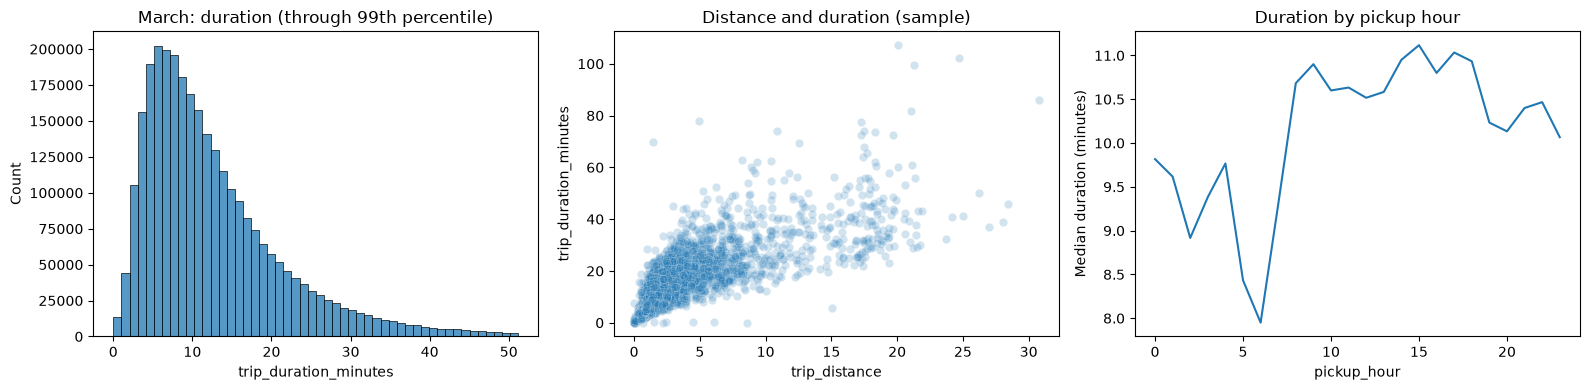

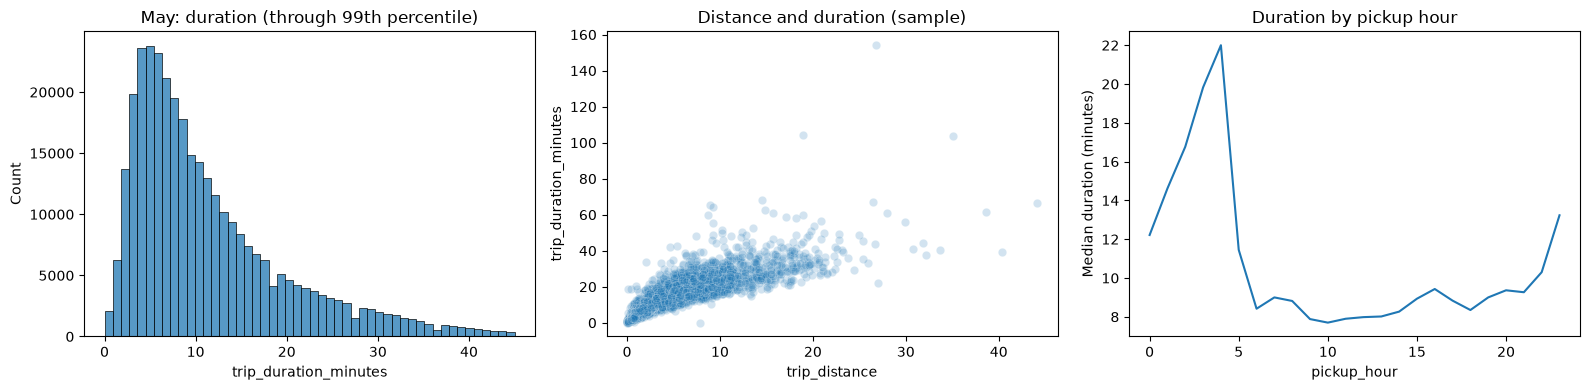

,trip_distance,passenger_count,pickup_hour,pickup_day_of_week,trip_duration_minutes
trip_distance,1.000000,0.016847,0.024930,0.011917,0.858601
passenger_count,0.016847,1.000000,0.033201,0.044761,0.019968
pickup_hour,0.024930,0.033201,1.000000,-0.039621,0.029772
pickup_day_of_week,0.011917,0.044761,-0.039621,1.000000,-0.045061
trip_duration_minutes,0.858601,0.019968,0.029772,-0.045061,1.000000


In [12]:
for month, frame in pristine.items():
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    # Limit the displayed range only; this does not remove rows from the data.
    upper = frame["trip_duration_minutes"].quantile(.99)
    sns.histplot(frame.loc[frame["trip_duration_minutes"].le(upper), "trip_duration_minutes"], bins=50, ax=axes[0])
    axes[0].set_title(f"{month}: duration (through 99th percentile)")
    sample = frame.sample(n=min(5000, len(frame)), random_state=42)
    sns.scatterplot(data=sample, x="trip_distance", y="trip_duration_minutes", alpha=.2, ax=axes[1])
    axes[1].set_title("Distance and duration (sample)")
    frame.groupby("pickup_hour")["trip_duration_minutes"].median().plot(ax=axes[2])
    axes[2].set_ylabel("Median duration (minutes)")
    axes[2].set_title("Duration by pickup hour")
    plt.tight_layout()
    plt.show()

columns = ["trip_distance", "passenger_count", "pickup_hour", "pickup_day_of_week", "trip_duration_minutes"]
display(pristine["March"][columns].corr(method="spearman"))


**My findings:** After applying my cleaning rules and outlier filters, I can see the patterns more clearly. For both March and May, most of the taxi trips have shorter duration, and there are less trips with very long duration.
Trip distance has the strongest relationship with trip duration. In March, the Spearman correlation between trip distance and trip duration is about 0.86, which is a strong positive correlation. I also observe this pattern in my scatterplots. When the trip distance increases, usually the trip duration also increases. So, trip distance seems to be one of the most important features for predicting the duration of a taxi trip.
The other features have much weaker correlations with trip duration. Passenger count has a correlation of about 0.02, pickup hour is about 0.03, and pickup day of week is about -0.05. Based on these numbers, passenger count and day of week do not show a strong relationship with trip duration.
However, pickup hour is interesting. Even though its correlation is very small, the graphs show that the median trip duration changes during different hours of the day. In March, some early morning hours have shorter trips, while the duration becomes higher during some daytime and afternoon hours. May has a different pattern, especially during very early morning hours where the median duration is much higher. This means that only looking at the correlation number may not show the complete relationship.
Overall, trip distance is the strongest feature related to trip duration in this analysis. Pickup hour may also be useful because the duration changes depending on the time of the day. Passenger count and day of week seem to have much weaker relationships with trip duration. This analysis also shows why it is important to look at both the graphs and correlation values when doing EDA.

## 7. My comparison of March and May
I compare the two months using the same cleaning rules. COVID is relevant context, but my observational comparison alone cannot prove the cause of the differences.


,cleaned_trip_count,median_duration_minutes,median_distance,missing_passenger_count_percent
March,2969781.0,10.416667,1.69,1.261911
May,337572.0,8.933333,2.05,17.075765


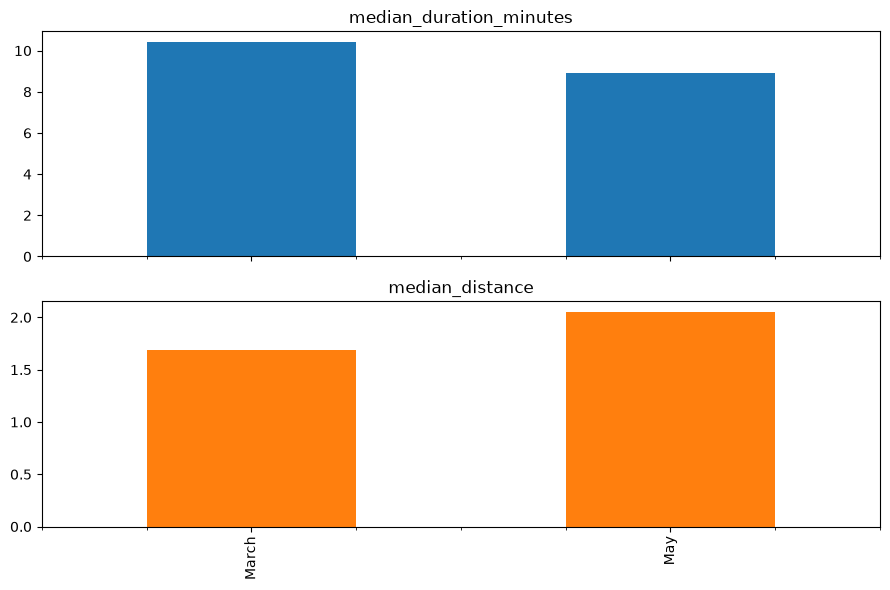

In [13]:
comparison = pd.DataFrame({month: {
    "cleaned_trip_count": len(frame),
    "median_duration_minutes": frame["trip_duration_minutes"].median(),
    "median_distance": frame["trip_distance"].median(),
    "missing_passenger_count_percent": frame["passenger_count"].isna().mean() * 100,
} for month, frame in pristine.items()}).T
display(comparison)
comparison[["median_duration_minutes", "median_distance"]].plot.bar(subplots=True, figsize=(9, 6), legend=False)
plt.tight_layout()
plt.show()


## 8. My TensorFlow Data Validation analysis
I generate graphical statistics for March and May, infer a schema from March, and validate May against that schema. I interpret detected anomalies as issues to investigate rather than automatic reasons to delete records.

My saved outputs below include the distribution comparison, inferred schema, and validation result. Schema validation checks structure and configured constraints; it does not establish that the two monthly distributions are identical.

In [14]:
import tensorflow_data_validation as tfdv

print("TFDV version:", tfdv.__version__)

TFDV version: 1.21.0


In [15]:
import tensorflow_data_validation as tfdv

# Use a focused set of columns to start. Expand for your final analysis.
validation_columns = ["trip_distance", "passenger_count", "pickup_hour", "pickup_day_of_week", "trip_duration_minutes"]
train_stats = tfdv.generate_statistics_from_dataframe(pristine["March"][validation_columns].reset_index(drop=True))
eval_stats = tfdv.generate_statistics_from_dataframe(pristine["May"][validation_columns].reset_index(drop=True))
tfdv.visualize_statistics(train_stats, eval_stats, lhs_name="March", rhs_name="May")
schema = tfdv.infer_schema(train_stats)
assert {f.name for f in schema.feature} == set(validation_columns)
tfdv.display_schema(schema)
anomalies = tfdv.validate_statistics(eval_stats, schema)
tfdv.display_anomalies(anomalies)

print("Schema anomalies:", len(anomalies.anomaly_info))
print("Validated features:", [f.name for f in schema.feature])


Schema anomalies: 0
Validated features: ['trip_distance', 'passenger_count', 'pickup_hour', 'pickup_day_of_week', 'trip_duration_minutes']


,Type,Presence,Valency,Domain
Feature name,,,,
'trip_distance',FLOAT,required,,-
'passenger_count',FLOAT,optional,single,-
'pickup_hour',INT,required,,-
'pickup_day_of_week',INT,required,,-
'trip_duration_minutes',FLOAT,required,,-


**My TFDV findings:** I used TFDV to compare the March training data with the May evaluation data after cleaning the outliers. The distributions of some features are different between March and May. Trip distance has a median of about 1.69 miles in March and 2.05 miles in May, which shows that the typical trip was a little longer in May. The average trip duration is about 13.11 minutes in March and 11.88 minutes in May. One important difference is the missing values in passenger count. March has about 1.26% missing passenger count, while May has about 17.08%, which is much higher. The pickup hour and day of week distributions also have some differences between the two months. TFDV helped to see these differences visually and compare the training and evaluation datasets. The schema was created using the March data and then May was checked against this schema. These results show that March and May do not have exactly the same data distribution, which is important if March data will be used to prepare a prediction system that will later be evaluated on May data.
My schema check reports its anomaly count above. The schema permits an optional passenger-count feature. Passing this check does not establish distribution equality, and I have not configured explicit drift thresholds.

## 9. My numeric inputs and target
I select recorded trip distance, passenger count, pickup hour, and weekday as four numeric inputs. I fill missing values using medians calculated from March only and apply the same values to May. I keep trip duration as a separate target.

I exclude categorical codes, text, original timestamps, and monetary fields from this compact input dataset. If I add categorical features later, I will encode them appropriately.

Drop-off time and final fare become known after the trip and can leak information about duration. Recorded trip distance is also a post-trip measurement, so a real pickup-time prediction system would need estimated route distance instead.

In [16]:
feature_columns = ["trip_distance", "passenger_count", "pickup_hour", "pickup_day_of_week"]
fill_values = pristine["March"][feature_columns].median()
X_train = pristine["March"][feature_columns].fillna(fill_values).astype(float)
X_eval = pristine["May"][feature_columns].fillna(fill_values).astype(float)
y_train = pristine["March"]["trip_duration_minutes"].copy()
y_eval = pristine["May"]["trip_duration_minutes"].copy()
assert np.isfinite(X_train.to_numpy()).all()
assert np.isfinite(X_eval.to_numpy()).all()
print("Training inputs:", X_train.shape, "Evaluation inputs:", X_eval.shape)
display(X_train.head())


Training inputs: (2969781, 4) Evaluation inputs: (337572, 4)


,trip_distance,passenger_count,pickup_hour,pickup_day_of_week
0,4.70,1.0,0.0,6.0
2,1.10,1.0,0.0,6.0
3,0.87,2.0,0.0,6.0
4,4.40,0.0,0.0,6.0
5,3.50,1.0,0.0,6.0


## 10. My data story and conclusions
### The data problems I found and how I handled them

During the EDA, I found several data quality problems. First, there were pickup dates that were outside of the correct month and even outside of 2020. There were also missing values, especially for passenger count. Some trip durations and trip distances were also unrealistic. For example, some trips had a duration close to 24 hours for only a few miles, and some distances were more than 100,000 miles, which is clearly not possible for a taxi trip.
After the first cleaning, March had 3,005,130 rows and May had 347,762 rows. I used a maximum duration of 180 minutes and a valid distance between 0 and 100 miles to remove unrealistic outliers. I also removed zero-distance trips. In March, 35,349 rows (1.176%) were removed by these outlier rules, leaving 2,969,781 pristine rows. In May, 10,190 rows (2.93%) were removed, leaving 337,572 pristine rows. There were no exact duplicate rows in either original dataset.

### My three strongest findings

My first and strongest finding is that trip distance has a strong relationship with trip duration. The Spearman correlation between distance and duration in March is about 0.86. The scatterplot also clearly shows that longer trips usually take more time.
My second finding is that pickup hour may also affect trip duration, but this relationship is not simple. Its Spearman correlation with duration is only about 0.03, but the hourly graphs show that median duration changes during different hours of the day. This shows that correlation alone cannot explain every pattern in the data.
My third finding is that March and May have important differences. May has much fewer taxi trips than March. Also, the typical May trip is a little longer in distance but shorter in duration. The TFDV analysis also showed a large difference in missing passenger count. It was about 1.26% in March but about 17.08% in May.

### My assessment of useful features and limitations

Based on this analysis, trip distance is the most useful feature for understanding trip duration. Pickup hour can also be useful because the graphs show different duration patterns depending on the time of day. Passenger count and pickup day of week have much weaker direct correlations with duration.
There are also some limitations. Correlation does not mean that one feature causes the trip duration. Also, pickup hour and day of week can have nonlinear patterns that are not completely represented by one correlation number. Another limitation is that the trip_distance in this dataset is the recorded final trip distance. If I extend this work to predict duration before a trip starts, I would need an estimated trip distance instead of using information that becomes known after the trip.

### What I learned from comparing March and May

March and May are not exactly from the same distribution. After cleaning, March has 2,969,781 trips, while May has only 337,572 trips. The median trip distance is also higher in May than March, while the median trip duration is lower. TFDV also showed differences in the distributions of some features and a much higher percentage of missing passenger count in May.
These months were during the COVID-19 period, so travel behavior was changing during this time. However, this analysis cannot prove that COVID was the direct reason for all of these differences. It only shows that the data changed between March and May. Because travel behavior can change over time, a future prediction system should be checked and updated with newer data instead of assuming that the March data will always represent future taxi trips.

### My recommendations

As a next step, I recommend using the pristine dataset for any future analysis or prediction model. Missing values should be handled consistently using information from the training data. The distributions of training and future evaluation data should also be checked regularly using tools such as TFDV because changes in the data can affect prediction performance.
I would also recommend studying more features, especially pickup and drop-off locations and time-related features. For a real prediction system, only information that is available when the prediction is made should be used, so features that become available after the trip should be avoided. Finally, using more recent taxi data would help to understand if the patterns found in March and May 2020 are still useful for predicting taxi trip duration today.

## My additional baseline analysis
I complete the January-versus-March extra credit in the next section. I retain March for training and May for evaluation; January is a descriptive baseline only.


## 11. My feature relevance ranking
I rank the selected features by the absolute Spearman association with duration. This is a descriptive relevance ranking, not a trained model's feature importance. I do not build a prediction model because the assignment does not require one. Pickup hour and weekday can have cyclic or nonlinear relationships that this ranking misses.

,spearman_with_duration,absolute_association
trip_distance,0.858601,0.858601
pickup_day_of_week,-0.045061,0.045061
pickup_hour,0.029772,0.029772
passenger_count,0.019968,0.019968


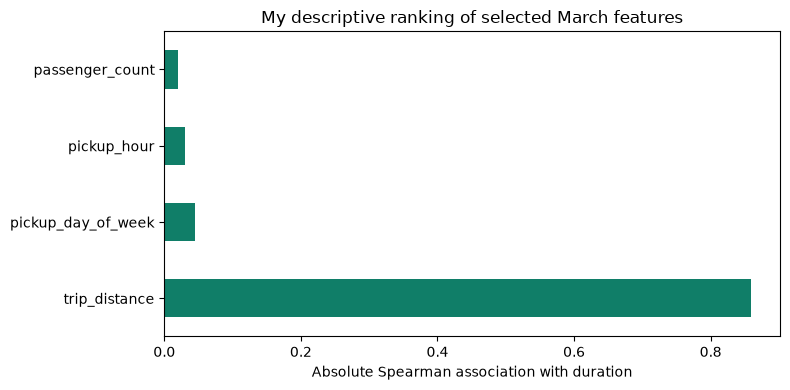

In [17]:
ranked_features = pristine["March"][feature_columns + ["trip_duration_minutes"]].corr(method="spearman")["trip_duration_minutes"].drop("trip_duration_minutes")
feature_relevance = pd.DataFrame({"spearman_with_duration": ranked_features, "absolute_association": ranked_features.abs()}).sort_values("absolute_association", ascending=False)
display(feature_relevance)
feature_relevance["absolute_association"].plot.barh(color="#107E68", figsize=(8, 4))
plt.xlabel("Absolute Spearman association with duration")
plt.title("My descriptive ranking of selected March features")
plt.tight_layout()
plt.show()


## 12. Extra credit: my January baseline versus March
January 2020 provides the assignment's baseline before the pandemic disruption. I compare it with March using exactly the same cleaning rules: intended pickup month, valid timestamps, positive finite duration, positive distance up to 100 miles, and duration up to 180 minutes. These are study limits and can exclude genuine exceptional trips.

I read all January records for the four required fields below. Reading a subset of columns reduces memory use; I do not sample rows for the summary statistics. January and March both contain 31 days. Daily plots include every calendar day, including zero-count days if any. The data and original file counts come from the [official NYC TLC trip records](https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page).

The local input is `data/yellow_tripdata_2020-01.parquet`. The download cell only fetches the official file when it is missing.

In [18]:
from urllib.request import urlretrieve
january_path = DATA_DIR / "yellow_tripdata_2020-01.parquet"
if not january_path.exists():
    urlretrieve("https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2020-01.parquet", january_path)

january_raw = pd.read_parquet(january_path, columns=["tpep_pickup_datetime", "tpep_dropoff_datetime", "trip_distance", "passenger_count"])
january_prepared = add_duration(january_raw)
january_clean, january_audit = clean_month(january_prepared, 1)
january_valid = (january_clean["trip_duration_minutes"].le(180)
                 & january_clean["trip_distance"].gt(0)
                 & january_clean["trip_distance"].le(100))
january_pristine = january_clean.loc[january_valid].copy()
print("January raw records:", len(january_raw))
display(january_audit)
print("January extra outlier removals:", len(january_clean) - len(january_pristine))
print("January retained records:", len(january_pristine))
display(january_raw.isna().sum().to_frame("missing_count"))
# Retain summaries and the final selected data, release intermediate copies.
january_raw_count = len(january_raw)
del january_raw, january_prepared, january_clean


January raw records: 6405008
January extra outlier removals: 77368
January retained records: 6320684


,rule,removed_at_this_step,remaining
0,valid timestamps,0,6405008
1,positive finite duration,4406,6400602
2,known nonnegative finite distance,2338,6398264
3,pickup in intended month,212,6398052


,missing_count
tpep_pickup_datetime,0
tpep_dropoff_datetime,0
trip_distance,0
passenger_count,65441


,raw_records,retained_records,retained_trips_per_calendar_day,median_duration_minutes,mean_duration_minutes,median_distance_miles,passenger_count_missing_percent
Month,,,,,,,
January,6405008.0,6320684.0,203893.032,10.500,13.159,1.61,0.991
March,3007687.0,2969781.0,95799.387,10.417,13.110,1.69,1.262


,January,March,March_change_percent
retained_records,6320684.000,2969781.000,-53.015
retained_trips_per_calendar_day,203893.032,95799.387,-53.015
median_duration_minutes,10.500,10.417,-0.794
median_distance_miles,1.610,1.690,4.969


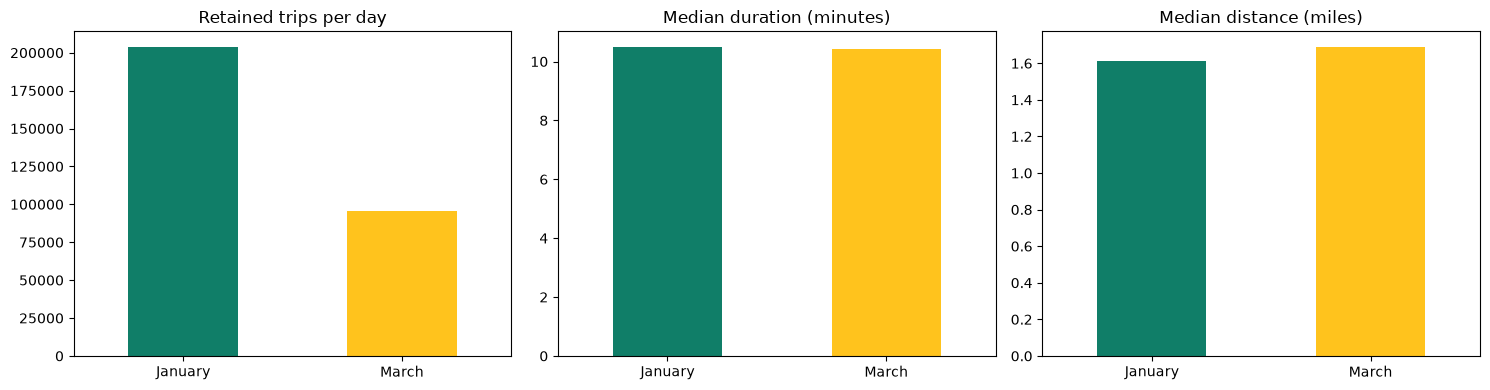

In [19]:
baseline_frames = {"January": january_pristine, "March": pristine["March"]}
baseline_summary = pd.DataFrame({month: {
    "raw_records": january_raw_count if month == "January" else len(raw["March"]),
    "retained_records": len(frame),
    "retained_trips_per_calendar_day": len(frame) / 31,
    "median_duration_minutes": frame["trip_duration_minutes"].median(),
    "mean_duration_minutes": frame["trip_duration_minutes"].mean(),
    "median_distance_miles": frame["trip_distance"].median(),
    "passenger_count_missing_percent": frame["passenger_count"].isna().mean() * 100,
} for month, frame in baseline_frames.items()}).T
baseline_summary.index.name = "Month"
display(baseline_summary.round(3))
changes = pd.DataFrame({
    "January": baseline_summary.loc["January"],
    "March": baseline_summary.loc["March"],
    "March_change_percent": (baseline_summary.loc["March"] / baseline_summary.loc["January"] - 1) * 100,
})
display(changes.loc[["retained_records", "retained_trips_per_calendar_day", "median_duration_minutes", "median_distance_miles"]].round(3))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, field, label in zip(axes,
    ["retained_trips_per_calendar_day", "median_duration_minutes", "median_distance_miles"],
    ["Retained trips per day", "Median duration (minutes)", "Median distance (miles)"]):
    baseline_summary[field].plot.bar(ax=ax, color=["#107E68", "#FFC31D"], rot=0)
    ax.set_title(label)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()


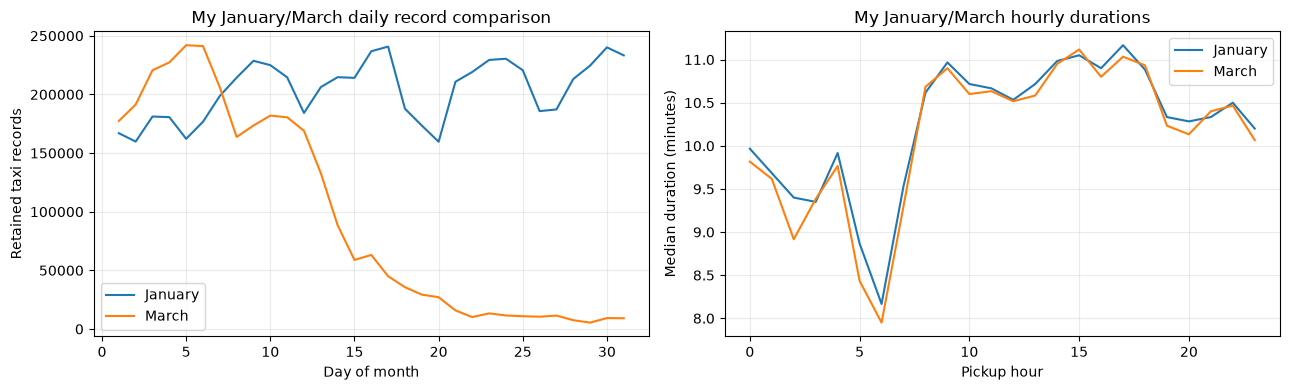

In [20]:
daily_baseline = {}
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for month, month_number in [("January", 1), ("March", 3)]:
    frame = baseline_frames[month]
    calendar = pd.date_range(f"2020-{month_number:02d}-01", periods=31, freq="D")
    daily = frame.groupby(frame["tpep_pickup_datetime"].dt.floor("D")).size().reindex(calendar, fill_value=0)
    daily_baseline[month] = daily
    axes[0].plot(calendar.day, daily.values, label=month)
    hourly = frame.groupby("pickup_hour")["trip_duration_minutes"].median()
    axes[1].plot(hourly.index, hourly.values, label=month)
axes[0].set(title="My January/March daily record comparison", xlabel="Day of month", ylabel="Retained taxi records")
axes[1].set(title="My January/March hourly durations", xlabel="Pickup hour", ylabel="Median duration (minutes)")
for ax in axes:
    ax.legend()
    ax.grid(alpha=.25)
plt.tight_layout()
plt.show()


In [21]:
jan = baseline_summary.loc["January"]
mar = baseline_summary.loc["March"]
volume_change = (mar["retained_records"] / jan["retained_records"] - 1) * 100
duration_change = (mar["median_duration_minutes"] / jan["median_duration_minutes"] - 1) * 100
distance_change = (mar["median_distance_miles"] / jan["median_distance_miles"] - 1) * 100
extra_findings = f"""### My extra-credit findings
I retained **{int(jan['retained_records']):,} January rides** and **{int(mar['retained_records']):,} March rides** after applying the same rules. March's retained trip count changed by **{volume_change:+.1f}%** relative to January. Because both months have 31 days, the percentage change in average daily retained records is the same.

Median ride duration changed from **{jan['median_duration_minutes']:.2f} minutes in January** to **{mar['median_duration_minutes']:.2f} minutes in March** (**{duration_change:+.1f}%**). Median recorded distance changed from **{jan['median_distance_miles']:.2f} miles** to **{mar['median_distance_miles']:.2f} miles** (**{distance_change:+.1f}%**).

My daily chart shows whether the March change occurred evenly across the month or varied over time. The comparison is consistent with changing travel conditions during the pandemic period, but it does not isolate COVID as the cause. Seasonality, route mix, reporting differences, and my cleaning rules may also affect the results.

I conclude that a January baseline helps show how unusual March was. I would check later data and monitor distribution changes before assuming a single month's patterns represent future rides.
"""
from IPython.display import Markdown
display(Markdown(extra_findings))


### My extra-credit findings
I retained **6,320,684 January rides** and **2,969,781 March rides** after applying the same rules. March's retained trip count changed by **-53.0%** relative to January. Because both months have 31 days, the percentage change in average daily retained records is the same.

Median ride duration changed from **10.50 minutes in January** to **10.42 minutes in March** (**-0.8%**). Median recorded distance changed from **1.61 miles** to **1.69 miles** (**+5.0%**).

My daily chart shows whether the March change occurred evenly across the month or varied over time. The comparison is consistent with changing travel conditions during the pandemic period, but it does not isolate COVID as the cause. Seasonality, route mix, reporting differences, and my cleaning rules may also affect the results.

I conclude that a January baseline helps show how unusual March was. I would check later data and monitor distribution changes before assuming a single month's patterns represent future rides.


### What I see in the daily chart
January's daily trip counts fluctuate across the month. March begins with comparable daily counts, then shows a sharp decline around mid-month and stays much lower toward the end. This explains why the monthly volume comparison changes strongly even though the median duration and distance change relatively little. A monthly median alone would miss this within-month change.

My hourly median duration curves for January and March are similar. I treat this as an aggregate observation, not proof that individual routes or traffic conditions stayed the same.

## 13. My workflow and reproducibility
GraphViz illustrates my analysis sequence. TFDV uses Apache Beam as a dependency; a separate Beam pipeline is not a stated assignment requirement. The dependency report near the start documents the actual installed versions.

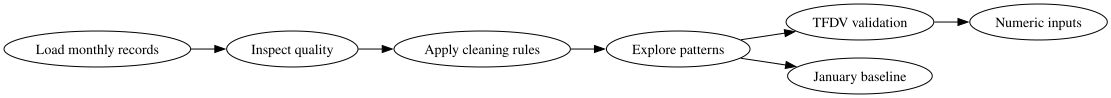

In [22]:
from graphviz import Digraph
workflow = Digraph("taxi_workflow", graph_attr={"rankdir": "LR"})
for key, label in [("load", "Load monthly records"), ("inspect", "Inspect quality"), ("clean", "Apply cleaning rules"), ("eda", "Explore patterns"), ("validate", "TFDV validation"), ("inputs", "Numeric inputs"), ("baseline", "January baseline")]:
    workflow.node(key, label)
for a,b in [("load","inspect"),("inspect","clean"),("clean","eda"),("eda","validate"),("validate","inputs"),("eda","baseline")]:
    workflow.edge(a,b)
display(workflow)


## 14. My requirement checklist

| Assignment requirement | Evidence in this notebook |
| --- | --- |
| March 2020 training and May 2020 evaluation | Data sources, loading, separate `X_train` and `X_eval` |
| Missing/null/NaN investigation | Raw missing-value tables for all columns |
| Outlier investigation and handling | Quantiles, extreme records, explicit limits, removal audit |
| Numeric final data | Four selected numeric inputs, March-only imputation, finite-value assertions |
| List data types | Semantic type table and actual pandas dtypes |
| Classic pandas/NumPy EDA | Summaries, distributions, scatterplots, hourly patterns, correlations |
| TFDV graphical statistics and validation | March/May comparison, inferred schema, May anomalies |
| Feature relationships and relevance | Correlations, grouped time plots, descriptive feature ranking |
| COVID time-window interpretation | March/May conclusions and January baseline limitations |
| Communicate findings and recommendations | My data story and extra-credit findings |
| January versus March extra credit | Full-row baseline summaries, daily/hourly plots, numeric interpretation |
| Required packages | Version report for TFDV, Apache Beam, GraphViz and system `dot` |
| One notebook with code and outputs | All analysis and saved outputs in this `.ipynb` file |

I do not claim causal effects, model accuracy, or fitted-model importance. My final numeric table deliberately excludes other raw columns, with reasons documented in the data-type and input sections.


## 15. My project in very simple words
A **dataset** is a big pile of taxi ride cards. Each **row** is one ride. A **column** is one kind of information, such as distance.

I act like a detective. **EDA** means looking carefully at the cards before building anything. **Missing data** means part of a card is blank. An **outlier** is a very unusual card that I investigate. **Cleaning** means applying clear rules so I know which cards I am studying.

My **target** is how many minutes the ride takes. A **feature** is a clue that might help explain that time. A **chart** turns many cards into a picture. The **median** is the middle number after sorting. The **mean** is the total divided by how many numbers there are.

**Correlation** tells me whether two clues tend to change together. It cannot prove that one causes the other. Distance and duration have a strong positive correlation here: farther rides usually take longer.

**TFDV** is my automatic card inspector. Its **schema** is a rule sheet describing the expected data. An **anomaly** is a rule violation. **Distribution shift** means the pile of cards has changed, even if every card still follows the rule sheet. **Apache Beam** helps data tools process information. **GraphViz** draws the workflow map.

March is my practice/reference pile. May is a later checking pile. January is my earlier comparison pile for extra credit. I do not train an AI model in this project.

**Imputation** fills a blank using a stated rule. I use March's middle passenger count for missing input values in both months. **Leakage** is using a clue I would only learn after the ride, like its actual finish time. A future prediction must use clues available when the prediction is made.
